# New THINGS head (1306 non-overlapping concepts)

Linear(512, 1306) on the frozen pretrained CordsNet-R8 features (classifier input, steps 70-99); CordsNet's weighted CE, true THINGS labels; AdamW, weight decay on the weights only; lr 1e-3 cosine to 0, 40 epochs.
Train 13,060 images (10 per concept), val 1,306 (1 per concept). Two selections over weight decay x epoch: **top1** = best val top-1 at the last step (200 ms), **ce** = lowest val CE (steps 70-99).
Chance: top-1 1/1306 = 0.08%, top-5 0.38%.

Input: `Round3/outputs/things_head/cosine_ep40/` (`history.csv`, `results_top1.npz`, `results_ce.npz`, `config.json`; from `Round3/things_head/train_head.py`, copied from Torch).

In [5]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CN = Path("~/Desktop/DynVision/CordsNet").expanduser()
out = CN / "Round3/outputs/things_head/cosine_ep40"
h = pd.read_csv(out / "history.csv")
res = {sel: np.load(out / f"results_{sel}.npz") for sel in ["top1", "ce"]}
cfg = json.load(open(out / "config.json"))
wds = sorted(h["weight_decay"].unique())
colors = ["#2a78d6", "#eb6834", "#1a9e77", "#8e44ad", "#c0392b"]
color = {wd: colors[i] for i, wd in enumerate(wds)}
marker = {"top1": "o", "ce": "s"}
print(cfg)
for sel, r in res.items():
    print(f"selected by {sel}: weight decay {float(r['weight_decay']):g}, epoch {int(r['epoch'])}")

{'features': 'CordsNet/Round3/outputs/things_head/features.npz', 'out_dir': 'CordsNet/Round3/outputs/things_head/cosine_ep40', 'weight_decays': [0.0, 0.01, 0.1, 1.0], 'lr': 0.001, 'epochs': 40, 'batch_size': 256, 'seed': 2723, 'device': 'cuda'}
selected by top1: weight decay 1, epoch 31
selected by ce: weight decay 1, epoch 40


## 1. Per weight decay

For each selection: the best epoch and its val top-1 / top-5 / CE, train top-1. Last column: val top-1 at the last epoch.

In [6]:
rows = []
for wd in wds:
    g = h[h["weight_decay"] == wd]
    bt, bc = g.loc[g["val_top1"].idxmax()], g.loc[g["val_ce"].idxmin()]
    rows.append({"weight decay": wd,
                 "top1: epoch": int(bt["epoch"]), "top1: val top-1": bt["val_top1"], "top1: val top-5": bt["val_top5"], "top1: val CE": bt["val_ce"],
                 "ce: epoch": int(bc["epoch"]), "ce: val top-1": bc["val_top1"], "ce: val top-5": bc["val_top5"], "ce: val CE": bc["val_ce"],
                 "train top-1, last epoch": g["train_top1"].iloc[-1], "val top-1, last epoch": g["val_top1"].iloc[-1],
                 "|W| per class, last epoch": g["W_norm"].iloc[-1]})
table = pd.DataFrame(rows).set_index("weight decay")
table["selected"] = [" ".join(sel for sel, r in res.items() if float(r["weight_decay"]) == wd) for wd in table.index]
table.round(4).T

weight decay,0.00,0.01,0.10,1.00
top1: epoch,31,31,31,31
top1: val top-1,0.585,0.585,0.5911,0.6325
top1: val top-5,0.8139,0.8147,0.8139,0.8346
top1: val CE,1.9597,1.9526,1.8955,1.6971
ce: epoch,31,31,31,40
ce: val top-1,0.585,0.585,0.5911,0.6302
ce: val top-5,0.8139,0.8147,0.8139,0.8346
ce: val CE,1.9597,1.9526,1.8955,1.6957
"train top-1, last epoch",1.0,1.0,1.0,1.0
"val top-1, last epoch",0.5789,0.5804,0.5881,0.6302


## 2. Learning curves

Left: top-1 (solid val, dashed train). Right: val CE. Circle: selected by top1; square: selected by ce.

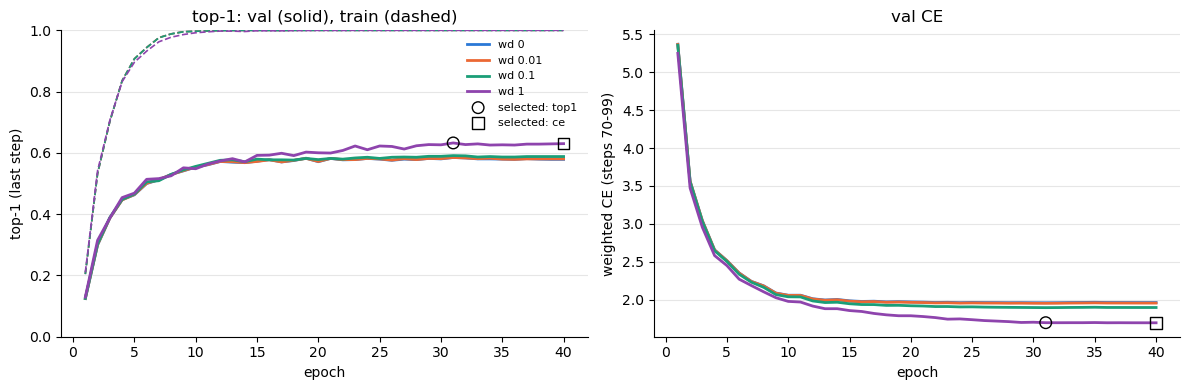

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for wd in wds:
    g = h[h["weight_decay"] == wd]
    axes[0].plot(g["epoch"], g["val_top1"], color=color[wd], lw=2, label=f"wd {wd:g}")
    axes[0].plot(g["epoch"], g["train_top1"], color=color[wd], lw=1.2, ls="--")
    axes[1].plot(g["epoch"], g["val_ce"], color=color[wd], lw=2, label=f"wd {wd:g}")
for sel, r in res.items():
    pt = h[(h["weight_decay"] == float(r["weight_decay"])) & (h["epoch"] == int(r["epoch"]))]
    for ax, col in [(axes[0], "val_top1"), (axes[1], "val_ce")]:
        ax.scatter(pt["epoch"], pt[col], s=70, marker=marker[sel], facecolor="none", edgecolor="k", zorder=5, label=f"selected: {sel}")
axes[0].set(xlabel="epoch", ylabel="top-1 (last step)", title="top-1: val (solid), train (dashed)", ylim=(0, 1))
axes[1].set(xlabel="epoch", ylabel="weighted CE (steps 70-99)", title="val CE")
for ax in axes:
    ax.grid(axis="y", color="0.9")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

Accuracy top-1 on the left, and validation CE on the right.  
Weight decay 1 is the best, and there is no major difference between top1 best epoch and ce best epoch.

## 3. The two selected heads: accuracy over the CE steps

Solid: val top-1; dotted: val top-5; dashed: train top-1.

top1: last step val top-1 0.6325, top-5 0.8346, val CE 1.697; train top-1 1.0000
ce: last step val top-1 0.6302, top-5 0.8346, val CE 1.696; train top-1 1.0000


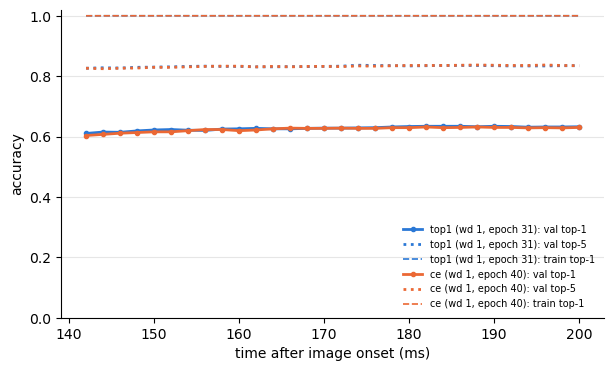

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
sel_color = {"top1": "#2a78d6", "ce": "#eb6834"}
for sel, r in res.items():
    t_ms = (r["steps"] + 1) * 2
    name = f"{sel} (wd {float(r['weight_decay']):g}, epoch {int(r['epoch'])})"
    ax.plot(t_ms, r["val_top1_t"], color=sel_color[sel], lw=2, marker="o", ms=3, label=f"{name}: val top-1")
    ax.plot(t_ms, r["val_top5_t"], color=sel_color[sel], lw=2, ls=":", label=f"{name}: val top-5")
    ax.plot(t_ms, r["train_top1_t"], color=sel_color[sel], lw=1.2, ls="--", label=f"{name}: train top-1")
    print(f"{sel}: last step val top-1 {r['val_top1_t'][-1]:.4f}, top-5 {r['val_top5_t'][-1]:.4f}, val CE {float(r['val_ce']):.3f}; "
          f"train top-1 {r['train_top1_t'][-1]:.4f}")
ax.set(xlabel="time after image onset (ms)", ylabel="accuracy", ylim=(0, 1.02))
ax.grid(axis="y", color="0.9")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=7, loc="lower right")
plt.show()

## Summary and selected head

**Selected head: weight decay 1, epoch 40** (selected by lowest val CE; `best_head_ce.pt`, `results_ce.npz`).

| | val top-1 | val top-5 | val CE (steps 70-99) | train top-1 |
|---|---|---|---|---|
| selected head (wd 1, epoch 40), last step (200 ms) | 0.630 | 0.835 | 1.696 | 1.000 |
| chance (1306 classes) | 0.0008 | 0.0038 | | |

- **Weight decay matters (unlike the first run with a constant lr).** wd 0 / 0.01 / 0.1 plateau at val top-1 0.585-0.591 (val CE 1.90-1.96); wd 1 reaches 0.630 (val CE 1.70). Same initialization, batch order and val images for every wd, so the comparison is paired; val CE (continuous, less noisy than top-1) agrees.
- **Both selection criteria pick wd 1**: top-1 at epoch 31 (val top-1 0.633), CE at epoch 40 (0.630; a difference of 3 images out of 1306). We use the CE-selected head: it is the end of the cosine schedule (no lucky peak), CE is the less noisy criterion, and the head is used in a CE loss downstream.
- **Stable training**: lr 1e-3 cosine to 0 removed the collapses seen with a constant lr; no val top-1 drop and no val CE increase late in training.
- **Overfitting without loss of generalization**: train top-1 reaches 1.0 by epoch ~10 for every wd, but val top-1 stays on its plateau and val CE keeps decreasing.
- **Stable over the CE window**: val top-1 rises slowly from 0.61 (142 ms) to 0.63 (200 ms); top-5 stays at 0.83-0.835.
- wd 1 is the edge of the grid and its val CE was still decreasing at epoch 40, so a larger wd might help slightly; not pursued, since the head is only the starting point and is trained further in Round 3.
- Val numbers are slightly optimistic (selection over 4 wd x 40 epochs); unbiased numbers will come from the test split.

**Use in Round 3**: initialization of the THINGS head (1306 non-overlapping concepts), parallel to the ImageNet head on the same 512-d classifier input. wd 1 was only for training this head on fixed features; Round 3 fine-tunes the whole model (backbone + both heads) with its own settings (AdamW, wd 0.01, lr 3e-5 cosine to 0).